<a href="https://colab.research.google.com/github/iceik973-dotcom/ML1/blob/main/%D0%A2%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%B5_%D0%B7%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_ML_%D0%B4%D0%B6%D1%83%D0%BD%D1%96%D0%BE%D1%80_%D0%93%D1%80%D0%B8%D0%B3%D0%BE%D1%80%D0%B8%D1%88%D0%B5%D0%BD_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Прогнозування відтоку клієнтів
**Практична робота з машинного навчання**

Мета: проаналізувати дані клієнтів, підготувати ознаки, порівняти моделі класифікації, вибрати найкращу та виконати прогноз для нового клієнта. Запускайте комірки послідовно в Google Colab.

## 1. Імпорт бібліотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
import warnings
warnings.filterwarnings('ignore')
RANDOM_STATE = 42

## 2. Завантаження набору даних
Використовується відкритий набір **IBM Telco Customer Churn**. Цільова змінна `Churn`: Yes — клієнт пішов, No — залишився.

In [2]:
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
try:
    df = pd.read_csv(url)
except Exception as exc:
    raise RuntimeError('Не вдалося завантажити CSV. Перевірте інтернет-з’єднання в Colab.') from exc
print('Розмір набору:', df.shape)
display(df.head())

Розмір набору: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Первинний аналіз даних

In [3]:
print('Типи даних та пропуски:')
df.info()
print('\nРозподіл цільової змінної:')
display(df['Churn'].value_counts().to_frame('Кількість'))
print('\nДублікати:', df.duplicated().sum())
print('\nПропущені значення:')
display(df.isna().sum().sort_values(ascending=False).head(12))

Типи даних та пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  

,Кількість
Churn,
No,5174
Yes,1869



Дублікати: 0

Пропущені значення:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


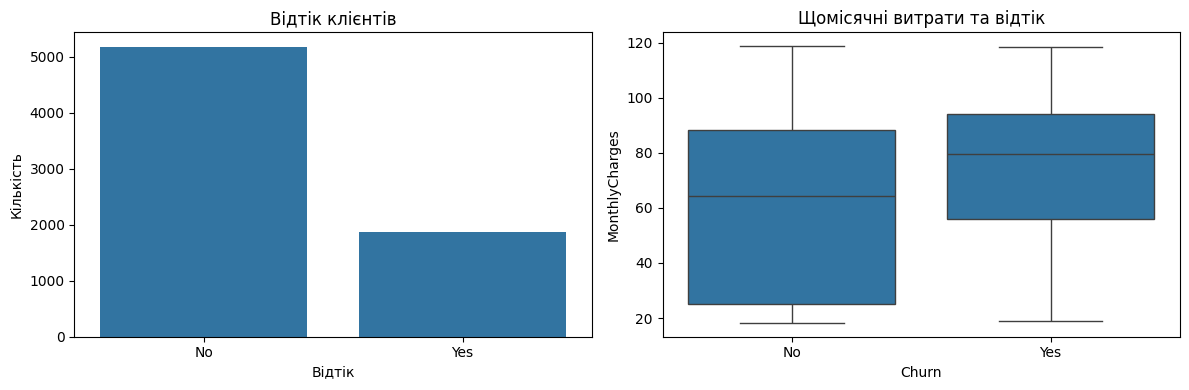

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Churn', ax=axes[0])
axes[0].set_title('Відтік клієнтів')
axes[0].set_xlabel('Відтік')
axes[0].set_ylabel('Кількість')
sns.boxplot(data=df.assign(MonthlyCharges=pd.to_numeric(df['MonthlyCharges'], errors='coerce')), x='Churn', y='MonthlyCharges', ax=axes[1])
axes[1].set_title('Щомісячні витрати та відтік')
plt.tight_layout()
plt.show()

## 4. Підготовка даних
Ідентифікатор клієнта не використовується як ознака. `TotalCharges` перетворюється на число, порожні значення обробляються у конвеєрі. Навчальна і тестова вибірки розділяються до налаштування моделей.

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
y = df['Churn'].map({'No': 0, 'Yes': 1})
X = df.drop(columns=['Churn', 'customerID'])
assert y.notna().all(), 'Невідомі значення цільової змінної'
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
])
print('Навчальна вибірка:', X_train.shape, '| Тестова:', X_test.shape)
print('Числові ознаки:', numeric_features)
print('Категоріальні ознаки:', categorical_features)

Навчальна вибірка: (5634, 19) | Тестова: (1409, 19)
Числові ознаки: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Категоріальні ознаки: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 5. Навчання та порівняння моделей
Порівнюються логістична регресія, випадковий ліс і градієнтний бустинг. Для оцінки застосовуються Accuracy, Precision, Recall, F1 і ROC-AUC.

In [6]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1500, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE)
}
trained_models = {}
results = []
for name, estimator in models.items():
    pipeline = Pipeline([('preprocess', preprocessor), ('model', estimator)])
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]
    results.append({'Модель': name, 'Accuracy': accuracy_score(y_test, pred),
                    'Precision': precision_score(y_test, pred, zero_division=0),
                    'Recall': recall_score(y_test, pred, zero_division=0),
                    'F1': f1_score(y_test, pred, zero_division=0),
                    'ROC-AUC': roc_auc_score(y_test, prob)})
    trained_models[name] = pipeline
results_df = pd.DataFrame(results).sort_values('F1', ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
1,Gradient Boosting,0.8062,0.6735,0.5241,0.5895,0.8434
2,Random Forest,0.7757,0.6000,0.4652,0.5241,0.8186


## 6. Підбір гіперпараметрів
Параметри логістичної регресії та випадкового лісу підбираються за F1 на навчальній вибірці за допомогою 3-кратної стратифікованої кросвалідації.

In [7]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search_spaces = {
    'Logistic Regression (tuned)': (LogisticRegression(max_iter=1500, random_state=RANDOM_STATE), {'model__C': [0.1, 1, 10], 'model__class_weight': [None, 'balanced']}),
    'Random Forest (tuned)': (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), {'model__n_estimators': [100, 200], 'model__max_depth': [None, 10], 'model__min_samples_leaf': [1, 3]})
}
for name, (estimator, params) in search_spaces.items():
    search = GridSearchCV(Pipeline([('preprocess', preprocessor), ('model', estimator)]), params, scoring='f1', cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned = search.best_estimator_
    pred = tuned.predict(X_test)
    prob = tuned.predict_proba(X_test)[:, 1]
    results.append({'Модель': name, 'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, zero_division=0), 'Recall': recall_score(y_test, pred, zero_division=0), 'F1': f1_score(y_test, pred, zero_division=0), 'ROC-AUC': roc_auc_score(y_test, prob)})
    trained_models[name] = tuned
    print(name, '| Найкращі параметри:', search.best_params_, '| CV F1:', round(search.best_score_, 4))
results_df = pd.DataFrame(results).sort_values('F1', ascending=False).reset_index(drop=True)
display(results_df.round(4))

Logistic Regression (tuned) | Найкращі параметри: {'model__C': 1, 'model__class_weight': 'balanced'} | CV F1: 0.6291
Random Forest (tuned) | Найкращі параметри: {'model__max_depth': 10, 'model__min_samples_leaf': 3, 'model__n_estimators': 100} | CV F1: 0.5776


,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression (tuned),0.7381,0.5043,0.7834,0.6136,0.8413
1,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
2,Gradient Boosting,0.8062,0.6735,0.5241,0.5895,0.8434
3,Random Forest (tuned),0.8013,0.6655,0.5053,0.5745,0.8408
4,Random Forest,0.7757,0.6000,0.4652,0.5241,0.8186


## 7. Вибір найкращої моделі та візуалізація результатів
Модель обирається за найбільшим F1 на тестовій вибірці (для навчального порівняння). Для суворої оцінки на нових даних варто використовувати окрему фінальну вибірку.

Найкраща модель: Logistic Regression (tuned)
              precision    recall  f1-score   support

   Залишився       0.90      0.72      0.80      1035
       Пішов       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



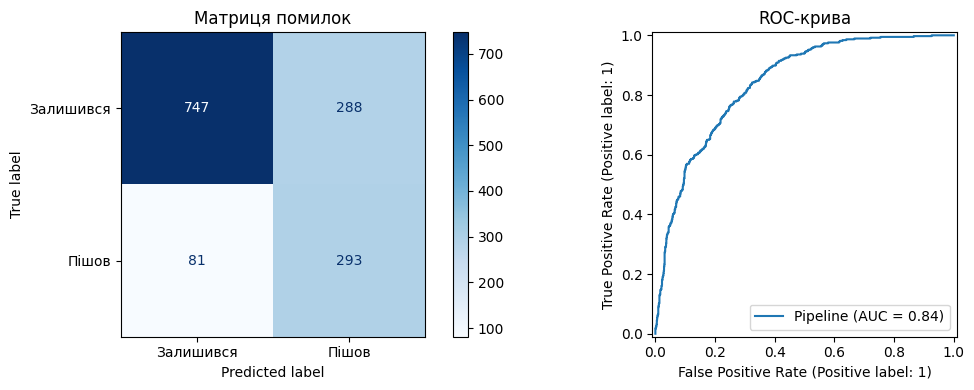

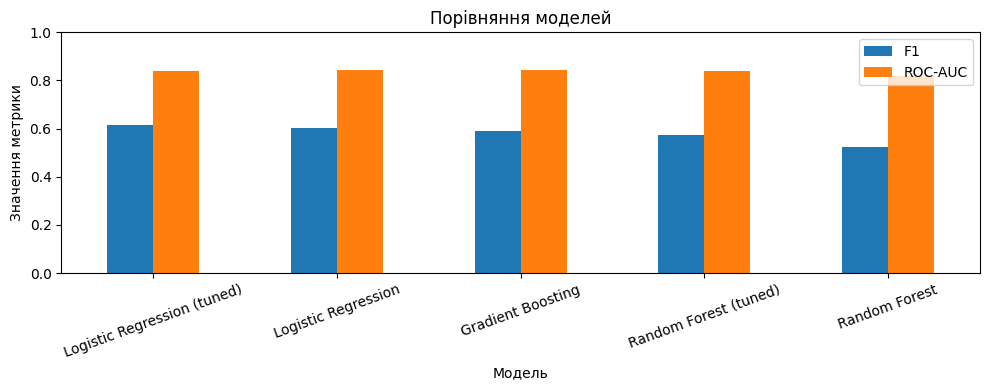

In [8]:
best_name = results_df.iloc[0]['Модель']
best_model = trained_models[best_name]
y_pred = best_model.predict(X_test)
print('Найкраща модель:', best_name)
print(classification_report(y_test, y_pred, target_names=['Залишився', 'Пішов']))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=['Залишився', 'Пішов'], ax=axes[0], cmap='Blues')
axes[0].set_title('Матриця помилок')
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1])
axes[1].set_title('ROC-крива')
plt.tight_layout()
plt.show()
results_df.set_index('Модель')[['F1', 'ROC-AUC']].plot(kind='bar', figsize=(10, 4), rot=20, title='Порівняння моделей')
plt.ylabel('Значення метрики')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 8. Прогноз для нового клієнта
Нижче наведено приклад. Можна змінити значення у словнику `client_values` або ввімкнути інтерактивне введення через `input()`. Всі інші ознаки беруться з типового рядка навчальної вибірки.

In [9]:
# Типові значення: медіана для числових, найчастіша категорія для текстових.
client_values = {}
for col in numeric_features:
    client_values[col] = float(X_train[col].median())
for col in categorical_features:
    client_values[col] = X_train[col].mode(dropna=True).iloc[0]

# Власні характеристики клієнта (редагуйте за потреби):
client_values.update({
    'gender': 'Female',
    'SeniorCitizen': 0,
    'Partner': 'No',
    'Dependents': 'No',
    'tenure': 5,
    'PhoneService': 'Yes',
    'InternetService': 'Fiber optic',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 85.0,
    'TotalCharges': 425.0
})
new_client = pd.DataFrame([client_values], columns=X.columns)
display(new_client.T.rename(columns={0: 'Значення'}))
probability = best_model.predict_proba(new_client)[0, 1]
prediction = int(best_model.predict(new_client)[0])
print(f'Ймовірність відтоку: {probability:.1%}')
print('Прогноз:', 'Клієнт піде' if prediction == 1 else 'Клієнт залишиться')

,Значення
gender,Female
SeniorCitizen,0
Partner,No
Dependents,No
tenure,5
PhoneService,Yes
MultipleLines,No
InternetService,Fiber optic
OnlineSecurity,No
OnlineBackup,No


Ймовірність відтоку: 79.7%
Прогноз: Клієнт піде


### Необов’язково: введення характеристик вручну
Встановіть `interactive = True`, щоб програма запитала кожну ознаку. Enter залишає типове значення. Для категорій використовуйте варіанти, наведені у підказці.

In [10]:
interactive = False
if interactive:
    manual_values = client_values.copy()
    for col in X.columns:
        if col in numeric_features:
            answer = input(f'{col} (число, типово {manual_values[col]}): ').strip()
            if answer:
                manual_values[col] = float(answer.replace(',', '.'))
        else:
            choices = sorted(X_train[col].dropna().astype(str).unique())
            answer = input(f'{col} {choices} (типово {manual_values[col]}): ').strip()
            if answer:
                if answer not in choices:
                    raise ValueError(f'Для {col} виберіть одне зі значень: {choices}')
                manual_values[col] = answer
    entered_client = pd.DataFrame([manual_values], columns=X.columns)
    probability = best_model.predict_proba(entered_client)[0, 1]
    print(f'Ймовірність відтоку: {probability:.1%}')
    print('Прогноз:', 'Клієнт піде' if best_model.predict(entered_client)[0] == 1 else 'Клієнт залишиться')

## 9. Висновки

У роботі було досліджено прогнозування відтоку клієнтів на основі набору даних IBM Telco Customer Churn. Проведено аналіз даних, обробку пропусків та кодування категоріальних ознак. Було порівняно алгоритми логістичної регресії, випадкового лісу та градієнтного бустингу, а також виконано підбір параметрів. За результатами порівняння моделей було визначено найкращий алгоритм для прогнозування відтоку клієнтів. На основі обраної моделі реалізовано прогноз, який дозволяє визначити, чи залишиться клієнт, чи припинить користуватися послугами.